### Create a phenotype for each TE

In [19]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

te_expression=pd.read_csv("/groups/nordborg/projects/ddm1_resilencing/04_output/limma_output/accession_specific_effect/expression_salmon_limma_normilized_genes_signif_padj001_log2fc1_union_effect_wo_controls_batch_corrected_seq_date_selected_based_on_Col0_mean_centered.csv", sep=";",decimal=",")  

#te_expression_families=pd.read_csv("/groups/nordborg/projects/ddm1_resilencing/11_resources/ref_genome/tes_annotation_with_superfamily.csv", sep=",",decimal=",") 
#te_expression_families
#te_expression_families_selected = te_expression_families[te_expression_families['Alias']=="ATCOPIA93"]
#te_expression_families_selected
# Filter to get only TEs of the inteterest
#filtered_te_expression = te_expression[te_expression['Unnamed: 0'].isin(te_expression_families_selected['Name'])]
#te_expression=filtered_te_expression
#del te_expression['Unnamed: 0']
#te_expression

# Filter to get only significant TEs 
#te_expression_cmt2
#filtered_te_expression = te_expression[te_expression['Unnamed: 0'].isin(te_expression_cmt2['TE'])]
#te_expression=filtered_te_expression
#del te_expression['Unnamed: 0']


In [16]:
te_expression

In [20]:
## Filter out TEs based on the overlap with genes 
overlap_gene_id=pd.read_csv("/groups/nordborg/projects/ddm1_resilencing/04_output/te_filtering_overlap/filtered_atleast1bp_overalp_with_gene_id_list.csv", sep=",",decimal=",", header=None) 
# Filter overlapping genes 
te_expression= te_expression[~te_expression['X'].isin(overlap_gene_id[0])]
te_expression = te_expression.set_index('X')
te_expression

,F1_Col_9537_1_17222,F1_Col_15592_1_17222,F1_Col_9617_1_17222,F1_ddm1_7130_1_17222,F1_ddm1_8348_1_17222,F1_ddm1_9537_1_17222,F1_ddm1_15592_1_17222,F1_Col_9856_1_17222,F1_Col_6963_1_17222,F1_Col_7298_1_17222,...,F1_Col_6960_2_17608,F1_Col_9822_2_17608,F1_Col_8337_2_17608,F1_Col_7025_2_17608,F1_ddm1_6909_2_17608,F1_ddm1_7003_2_17608,F1_ddm1_6960_2_17608,F1_ddm1_9822_2_17608,F1_ddm1_8337_2_17608,F1_ddm1_7025_2_17608
X,,,,,,,,,,,,,,,,,,,,,
AT1TE14085,-1.119721,-1.119721,-1.119721,1.824930,1.988018,1.065209,2.056724,-1.119721,-1.119721,-1.119721,...,-1.204451,-1.204451,-1.204451,-1.204451,-1.293043,1.665119,2.995000,1.943173,1.448051,2.240785
AT1TE36035,-0.963265,-0.963265,-0.963265,-0.963265,1.751764,1.622628,-0.963265,-0.963265,-0.963265,-0.963265,...,-0.451216,-1.154523,-1.154523,-1.154523,1.444091,2.044219,0.790088,0.356213,1.817225,-1.154523
AT1TE36570,-1.538217,-1.538217,-1.538217,2.296028,1.421509,1.258030,2.335440,-1.538217,-1.538217,-1.538217,...,-0.574947,-1.683870,-1.683870,-1.683870,1.433020,1.866348,2.536960,0.645362,1.911169,1.580439
AT1TE38940,-2.847523,-2.847523,-2.847523,3.049087,3.036858,3.821434,3.797894,-2.847523,-2.847523,-2.847523,...,-2.840321,-2.840321,-2.840321,-2.840321,2.157128,3.667605,4.296592,1.953320,3.822658,2.441398
AT1TE40355,-1.191887,-1.191887,-1.191887,1.827701,0.927760,1.471482,2.099925,-1.191887,-1.191887,-1.191887,...,-1.393747,-1.393747,-1.393747,-1.393747,1.874686,1.974224,0.184054,1.379967,1.455421,1.805483
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
AT5TE61735,-1.261540,-1.261540,-1.261540,-1.261540,1.159606,1.397349,1.766261,-1.261540,-1.261540,-1.261540,...,-0.790487,-1.474161,-0.793872,-0.731601,1.204437,-0.149917,1.993408,1.778107,2.025030,1.679658
AT5TE63610,-1.825193,-2.762665,-2.762665,1.628370,2.086603,1.384723,1.616345,-2.762665,-2.762665,-2.762665,...,-2.551066,-2.107315,-2.551066,-2.551066,1.899292,-2.551066,2.237832,-1.639334,2.212497,1.706220
AT5TE65540,-3.088909,-3.088909,-3.088909,1.627336,3.141017,3.430327,3.352629,-3.088909,-3.088909,-3.088909,...,-3.165953,-3.165953,-3.165953,-3.165953,2.566590,3.116679,3.377547,2.686925,3.343221,3.057356


In [21]:
te_expression.head()
te_expression = te_expression.apply(pd.to_numeric, errors='coerce')
te_expression_log2=te_expression

In [81]:
# Remove ddm1 itself
#patterns_to_remove = ['ddm1_ct']

# Filter out columns where names end with any of the specified patterns
#columns_to_keep = [col for col in te_expression_log2.columns if not any(col.startswith(pattern) for pattern in patterns_to_remove)]

# Keep only the desired columns
#te_expression_log2 = te_expression_log2[columns_to_keep]
#te_expression_log2

In [82]:
#print(te_expression_log2.loc[:, ["F1_Col_Col_9617_1","F1_Col_Col_9617_2"]])

In [22]:
### Handle repeatable measurments of Col )
te_expression_log2=te_expression
filtered_te_expression_log2_t=te_expression_log2.transpose()
filtered_te_expression_log2_t = filtered_te_expression_log2_t.reset_index()
filtered_te_expression_log2_t

X,index,AT1TE14085,AT1TE36035,AT1TE36570,AT1TE38940,AT1TE40355,AT1TE41230,AT1TE42210,AT1TE42225,AT1TE42465,...,AT5TE48550,AT5TE48930,AT5TE49130,AT5TE51685,AT5TE54525,AT5TE61735,AT5TE63610,AT5TE65540,AT5TE74320,AT5TE79225
0,F1_Col_9537_1_17222,-1.119721,-0.963265,-1.538217,-2.847523,-1.191887,-2.423659,-1.079022,-2.701504,-0.951934,...,-1.181718,0.264740,-1.468529,-2.942378,-1.296851,-1.261540,-1.825193,-3.088909,-2.937194,-1.398787
1,F1_Col_15592_1_17222,-1.119721,-0.963265,-1.538217,-2.847523,-1.191887,-2.423659,-0.048980,-2.701504,-0.951934,...,-1.181718,-1.408076,-1.468529,-2.942378,-1.296851,-1.261540,-2.762665,-3.088909,-2.937194,-1.398787
2,F1_Col_9617_1_17222,-1.119721,-0.963265,-1.538217,-2.847523,-1.191887,-2.423659,-1.079022,-2.701504,-0.951934,...,-1.181718,-0.870394,-1.468529,-2.942378,-1.296851,-1.261540,-2.762665,-3.088909,1.568697,-1.398787
3,F1_ddm1_7130_1_17222,1.824930,-0.963265,2.296028,3.049087,1.827701,3.138849,1.769328,3.321681,1.764987,...,2.059677,0.333098,0.946745,3.156936,1.345936,-1.261540,1.628370,1.627336,0.322155,1.391620
4,F1_ddm1_8348_1_17222,1.988018,1.751764,1.421509,3.036858,0.927760,3.151048,2.430634,3.885912,0.472872,...,1.974867,0.418896,0.619581,2.645937,1.276385,1.159606,2.086603,3.141017,0.839157,1.189356
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1595,F1_ddm1_7003_2_17608,1.665119,2.044219,1.866348,3.667605,1.974224,4.119545,2.382618,3.480695,1.339532,...,1.020280,0.634970,0.253904,3.049001,-0.361028,-0.149917,-2.551066,3.116679,0.460653,-0.040708
1596,F1_ddm1_6960_2_17608,2.995000,0.790088,2.536960,4.296592,0.184054,1.672458,-1.115051,2.664359,1.087141,...,1.700325,1.995245,1.701290,3.519174,1.504446,1.993408,2.237832,3.377547,2.395659,1.067723
1597,F1_ddm1_9822_2_17608,1.943173,0.356213,0.645362,1.953320,1.379967,2.202956,1.483652,2.407016,0.189198,...,2.248705,-0.804629,0.779912,2.632439,1.413784,1.778107,-1.639334,2.686925,1.386670,1.280455
1598,F1_ddm1_8337_2_17608,1.448051,1.817225,1.911169,3.822658,1.455421,3.762493,0.872708,3.586751,0.722644,...,1.519883,-0.580485,0.599787,3.032933,1.282096,2.025030,2.212497,3.343221,2.819634,2.672536


In [23]:
#filtered_te_expression_log2_t=filtered_te_expression_log2_t["index"].str.extract(r"_([\d\.]+)$")[0].astype(float)
filtered_te_expression_log2_t["Replicate"] = filtered_te_expression_log2_t["index"].str.extract(r"_(\d+)_\d+$")[0].astype(float)
filtered_te_expression_log2_t["accession"] = filtered_te_expression_log2_t['index'].str.extract(r'(.*?)_\d+$')[0]
filtered_te_expression_log2_t

X,index,AT1TE14085,AT1TE36035,AT1TE36570,AT1TE38940,AT1TE40355,AT1TE41230,AT1TE42210,AT1TE42225,AT1TE42465,...,AT5TE49130,AT5TE51685,AT5TE54525,AT5TE61735,AT5TE63610,AT5TE65540,AT5TE74320,AT5TE79225,Replicate,accession
0,F1_Col_9537_1_17222,-1.119721,-0.963265,-1.538217,-2.847523,-1.191887,-2.423659,-1.079022,-2.701504,-0.951934,...,-1.468529,-2.942378,-1.296851,-1.261540,-1.825193,-3.088909,-2.937194,-1.398787,1.0,F1_Col_9537_1
1,F1_Col_15592_1_17222,-1.119721,-0.963265,-1.538217,-2.847523,-1.191887,-2.423659,-0.048980,-2.701504,-0.951934,...,-1.468529,-2.942378,-1.296851,-1.261540,-2.762665,-3.088909,-2.937194,-1.398787,1.0,F1_Col_15592_1
2,F1_Col_9617_1_17222,-1.119721,-0.963265,-1.538217,-2.847523,-1.191887,-2.423659,-1.079022,-2.701504,-0.951934,...,-1.468529,-2.942378,-1.296851,-1.261540,-2.762665,-3.088909,1.568697,-1.398787,1.0,F1_Col_9617_1
3,F1_ddm1_7130_1_17222,1.824930,-0.963265,2.296028,3.049087,1.827701,3.138849,1.769328,3.321681,1.764987,...,0.946745,3.156936,1.345936,-1.261540,1.628370,1.627336,0.322155,1.391620,1.0,F1_ddm1_7130_1
4,F1_ddm1_8348_1_17222,1.988018,1.751764,1.421509,3.036858,0.927760,3.151048,2.430634,3.885912,0.472872,...,0.619581,2.645937,1.276385,1.159606,2.086603,3.141017,0.839157,1.189356,1.0,F1_ddm1_8348_1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1595,F1_ddm1_7003_2_17608,1.665119,2.044219,1.866348,3.667605,1.974224,4.119545,2.382618,3.480695,1.339532,...,0.253904,3.049001,-0.361028,-0.149917,-2.551066,3.116679,0.460653,-0.040708,2.0,F1_ddm1_7003_2
1596,F1_ddm1_6960_2_17608,2.995000,0.790088,2.536960,4.296592,0.184054,1.672458,-1.115051,2.664359,1.087141,...,1.701290,3.519174,1.504446,1.993408,2.237832,3.377547,2.395659,1.067723,2.0,F1_ddm1_6960_2
1597,F1_ddm1_9822_2_17608,1.943173,0.356213,0.645362,1.953320,1.379967,2.202956,1.483652,2.407016,0.189198,...,0.779912,2.632439,1.413784,1.778107,-1.639334,2.686925,1.386670,1.280455,2.0,F1_ddm1_9822_2
1598,F1_ddm1_8337_2_17608,1.448051,1.817225,1.911169,3.822658,1.455421,3.762493,0.872708,3.586751,0.722644,...,0.599787,3.032933,1.282096,2.025030,2.212497,3.343221,2.819634,2.672536,2.0,F1_ddm1_8337_2


In [24]:
## Average repeatable measurments
filtered_te_expression_log2_t
filtered_te_expression_log2_t=filtered_te_expression_log2_t.drop(['index'], axis=1)
filtered_te_expression_log2_t['Replicate_Group'] = filtered_te_expression_log2_t['Replicate'].apply(lambda x: int(x))  # This keeps only the integer part of 'Replicate'
filtered_te_expression_log2_t
averaged_df = filtered_te_expression_log2_t.groupby(['accession', 'Replicate_Group']).mean().reset_index()
# Deop unnecessary columns
averaged_df=averaged_df.drop(['Replicate_Group'], axis=1)
averaged_df=averaged_df.drop(['Replicate'], axis=1)


ValueError: cannot convert float NaN to integer

In [86]:
transposed_df = averaged_df.transpose()
transposed_df.columns = averaged_df['accession'].values  # Set the accession column as column names
transposed_df = transposed_df.drop('accession', axis=0)
#transposed_df.columns = transposed_df.columns.str.replace('F1_Col_', '', regex=False).str.replace('F1_ddm1_', '', regex=False)
#transposed_df.columns = transposed_df.columns.str.replace('ct_col_', '', regex=False)
transposed_df

,F1_Col_10010_1,F1_Col_10010_2,F1_Col_10010_3,F1_Col_1002_2,F1_Col_1002_3,F1_Col_108_1,F1_Col_108_3,F1_Col_14319_1,F1_Col_14319_2,F1_Col_14319_3,...,F1_ddm1_9927_1,F1_ddm1_9927_2,F1_ddm1_9927_3,F1_ddm1_9933_1,F1_ddm1_9933_3,F1_ddm1_9938_2,F1_ddm1_9938_3,F1_ddm1_9972_1,F1_ddm1_9972_2,F1_ddm1_9972_3
TE_ID,,,,,,,,,,,,,,,,,,,,,
AT1TE35305,1.653241,0.306991,1.064508,2.385015,1.105381,1.688108,1.006211,3.417393,0.866029,1.531392,...,1.754281,2.125918,1.221832,2.08929,2.242427,2.094317,2.373195,0.306991,1.420186,1.33025
AT1TE41350,0.306991,0.306991,0.306991,0.306991,0.306991,0.925136,0.306991,0.306991,0.866029,0.306991,...,2.099581,2.125918,2.747095,0.880315,2.242427,1.812277,2.134918,1.663186,2.473618,1.555935
AT1TE45145,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,...,0.962939,0.306991,0.306991,2.260638,1.838472,2.71208,2.134918,0.306991,1.421737,2.931157
AT1TE45800,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,...,1.433279,2.418871,1.221832,1.499962,3.268653,1.718326,2.37517,1.88143,1.761277,0.306991
AT1TE46140,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.865102,0.306991,...,0.306991,1.851162,1.332639,4.503851,3.858897,2.603951,2.690174,4.350796,0.306991,2.612619
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
AT5TE45090,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,...,0.962939,0.306991,0.306991,3.445109,1.831406,1.461362,1.492942,2.812555,2.473618,2.557339
AT5TE46840,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,...,0.306991,1.902757,1.220477,2.670878,2.242427,2.093292,2.248471,1.663186,3.07596,2.665956
AT5TE47140,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,...,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,2.868567,2.776029,1.431006,1.1449


In [87]:
transposed_df[['F1_Col_10010_1', 'F1_ddm1_10010_1']]

,F1_Col_10010_1,F1_ddm1_10010_1
TE_ID,,
AT1TE35305,1.653241,2.232495
AT1TE41350,0.306991,1.644166
AT1TE45145,0.306991,1.52804
AT1TE45800,0.306991,1.354931
AT1TE46140,0.306991,0.306991
...,...,...
AT5TE45090,0.306991,2.042201
AT5TE46840,0.306991,2.709536
AT5TE47140,0.306991,1.332206


In [88]:
transposed_df.columns

Index(['F1_Col_10010_1', 'F1_Col_10010_2', 'F1_Col_10010_3', 'F1_Col_1002_2',
       'F1_Col_1002_3', 'F1_Col_108_1', 'F1_Col_108_3', 'F1_Col_14319_1',
       'F1_Col_14319_2', 'F1_Col_14319_3',
       ...
       'F1_ddm1_9927_1', 'F1_ddm1_9927_2', 'F1_ddm1_9927_3', 'F1_ddm1_9933_1',
       'F1_ddm1_9933_3', 'F1_ddm1_9938_2', 'F1_ddm1_9938_3', 'F1_ddm1_9972_1',
       'F1_ddm1_9972_2', 'F1_ddm1_9972_3'],
      dtype='object', length=1254)

In [89]:
from collections import defaultdict

# Group columns by accession ID (ignoring replicates)
samples_by_id = defaultdict(list)
for col in transposed_df.columns:
    # Split the column name and extract the accession and replicate
    parts = col.split("_")
    if len(parts) >= 4:  # Ensure we have enough parts
        accession_id = parts[2]  # Extract the numeric ID (e.g., '10010')
        replicate = parts[3]     # Extract the replicate number
        samples_by_id[f"{accession_id}_{replicate}"].append(col)

# Create sample pairs
sample_pairs = {}
for accession_replicate, samples in samples_by_id.items():
    col_samples = [s for s in samples if "Col" in s]
    ddm1_samples = [s for s in samples if "ddm1" in s]

    # Pair samples if both Col and ddm1 exist
    if col_samples and ddm1_samples:
        sample_pairs[col_samples[0]] = ddm1_samples[0]


# Print the resulting pairs
for col_sample, ddm1_sample in sample_pairs.items():
    print(f"Paired: {col_sample} <-> {ddm1_sample}")

# Print unpaired samples
all_col_samples = [col for col in transposed_df.columns if "Col" in col]
all_ddm1_samples = [col for col in transposed_df.columns if "ddm1" in col]
unpaired = [col for col in all_col_samples if col not in sample_pairs]
unpaired_ddm1 = [col for col in all_ddm1_samples if col not in sample_pairs.values()]
for sample in unpaired:
    print(f"No pair for: {sample}")
for sample in unpaired_ddm1:
    print(f"No pair for: {sample}")



Paired: F1_Col_10010_1 <-> F1_ddm1_10010_1
Paired: F1_Col_10010_2 <-> F1_ddm1_10010_2
Paired: F1_Col_10010_3 <-> F1_ddm1_10010_3
Paired: F1_Col_1002_2 <-> F1_ddm1_1002_2
Paired: F1_Col_1002_3 <-> F1_ddm1_1002_3
Paired: F1_Col_108_1 <-> F1_ddm1_108_1
Paired: F1_Col_108_3 <-> F1_ddm1_108_3
Paired: F1_Col_14319_1 <-> F1_ddm1_14319_1
Paired: F1_Col_14319_3 <-> F1_ddm1_14319_3
Paired: F1_Col_15560_1 <-> F1_ddm1_15560_1
Paired: F1_Col_15560_2 <-> F1_ddm1_15560_2
Paired: F1_Col_15560_3 <-> F1_ddm1_15560_3
Paired: F1_Col_15592_1 <-> F1_ddm1_15592_1
Paired: F1_Col_15592_2 <-> F1_ddm1_15592_2
Paired: F1_Col_15592_3 <-> F1_ddm1_15592_3
Paired: F1_Col_159_2 <-> F1_ddm1_159_2
Paired: F1_Col_159_3 <-> F1_ddm1_159_3
Paired: F1_Col_1853_2 <-> F1_ddm1_1853_2
Paired: F1_Col_1853_3 <-> F1_ddm1_1853_3
Paired: F1_Col_2171_1 <-> F1_ddm1_2171_1
Paired: F1_Col_2171_2 <-> F1_ddm1_2171_2
Paired: F1_Col_2171_3 <-> F1_ddm1_2171_3
Paired: F1_Col_2202_1 <-> F1_ddm1_2202_1
Paired: F1_Col_2202_2 <-> F1_ddm1_2202_2
Pa

In [90]:
sample_pairs.items()

dict_items([('F1_Col_10010_1', 'F1_ddm1_10010_1'), ('F1_Col_10010_2', 'F1_ddm1_10010_2'), ('F1_Col_10010_3', 'F1_ddm1_10010_3'), ('F1_Col_1002_2', 'F1_ddm1_1002_2'), ('F1_Col_1002_3', 'F1_ddm1_1002_3'), ('F1_Col_108_1', 'F1_ddm1_108_1'), ('F1_Col_108_3', 'F1_ddm1_108_3'), ('F1_Col_14319_1', 'F1_ddm1_14319_1'), ('F1_Col_14319_3', 'F1_ddm1_14319_3'), ('F1_Col_15560_1', 'F1_ddm1_15560_1'), ('F1_Col_15560_2', 'F1_ddm1_15560_2'), ('F1_Col_15560_3', 'F1_ddm1_15560_3'), ('F1_Col_15592_1', 'F1_ddm1_15592_1'), ('F1_Col_15592_2', 'F1_ddm1_15592_2'), ('F1_Col_15592_3', 'F1_ddm1_15592_3'), ('F1_Col_159_2', 'F1_ddm1_159_2'), ('F1_Col_159_3', 'F1_ddm1_159_3'), ('F1_Col_1853_2', 'F1_ddm1_1853_2'), ('F1_Col_1853_3', 'F1_ddm1_1853_3'), ('F1_Col_2171_1', 'F1_ddm1_2171_1'), ('F1_Col_2171_2', 'F1_ddm1_2171_2'), ('F1_Col_2171_3', 'F1_ddm1_2171_3'), ('F1_Col_2202_1', 'F1_ddm1_2202_1'), ('F1_Col_2202_2', 'F1_ddm1_2202_2'), ('F1_Col_2202_3', 'F1_ddm1_2202_3'), ('F1_Col_2276_2', 'F1_ddm1_2276_2'), ('F1_Col_227

In [91]:
transposed_df

,F1_Col_10010_1,F1_Col_10010_2,F1_Col_10010_3,F1_Col_1002_2,F1_Col_1002_3,F1_Col_108_1,F1_Col_108_3,F1_Col_14319_1,F1_Col_14319_2,F1_Col_14319_3,...,F1_ddm1_9927_1,F1_ddm1_9927_2,F1_ddm1_9927_3,F1_ddm1_9933_1,F1_ddm1_9933_3,F1_ddm1_9938_2,F1_ddm1_9938_3,F1_ddm1_9972_1,F1_ddm1_9972_2,F1_ddm1_9972_3
TE_ID,,,,,,,,,,,,,,,,,,,,,
AT1TE35305,1.653241,0.306991,1.064508,2.385015,1.105381,1.688108,1.006211,3.417393,0.866029,1.531392,...,1.754281,2.125918,1.221832,2.08929,2.242427,2.094317,2.373195,0.306991,1.420186,1.33025
AT1TE41350,0.306991,0.306991,0.306991,0.306991,0.306991,0.925136,0.306991,0.306991,0.866029,0.306991,...,2.099581,2.125918,2.747095,0.880315,2.242427,1.812277,2.134918,1.663186,2.473618,1.555935
AT1TE45145,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,...,0.962939,0.306991,0.306991,2.260638,1.838472,2.71208,2.134918,0.306991,1.421737,2.931157
AT1TE45800,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,...,1.433279,2.418871,1.221832,1.499962,3.268653,1.718326,2.37517,1.88143,1.761277,0.306991
AT1TE46140,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.865102,0.306991,...,0.306991,1.851162,1.332639,4.503851,3.858897,2.603951,2.690174,4.350796,0.306991,2.612619
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
AT5TE45090,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,...,0.962939,0.306991,0.306991,3.445109,1.831406,1.461362,1.492942,2.812555,2.473618,2.557339
AT5TE46840,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,...,0.306991,1.902757,1.220477,2.670878,2.242427,2.093292,2.248471,1.663186,3.07596,2.665956
AT5TE47140,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,...,0.306991,0.306991,0.306991,0.306991,0.306991,0.306991,2.868567,2.776029,1.431006,1.1449


In [92]:
# Create a difference dataframe 
diff_df = {}
for col, ddm1 in sample_pairs.items():
    if ddm1 is not None and col in transposed_df and ddm1 in transposed_df and col is not None:
        if transposed_df[col] is not None and transposed_df[ddm1] is not None:
            diff_df[col] = transposed_df[ddm1] - transposed_df[col]
            print(transposed_df[col])
        else:
            diff_df[col] = np.nan  # Use consistent data type
    else:
        diff_df[col] = np.nan # Default value if pair doesn't exist


TE_ID
AT1TE35305    1.653241
AT1TE41350    0.306991
AT1TE45145    0.306991
AT1TE45800    0.306991
AT1TE46140    0.306991
                ...   
AT5TE45090    0.306991
AT5TE46840    0.306991
AT5TE47140    0.306991
AT5TE47525    0.306991
AT5TE52400    0.306991
Name: F1_Col_10010_1, Length: 134, dtype: object
TE_ID
AT1TE35305    0.306991
AT1TE41350    0.306991
AT1TE45145    0.306991
AT1TE45800    0.306991
AT1TE46140    0.306991
                ...   
AT5TE45090    0.306991
AT5TE46840    0.306991
AT5TE47140    0.306991
AT5TE47525    0.306991
AT5TE52400    0.306991
Name: F1_Col_10010_2, Length: 134, dtype: object
TE_ID
AT1TE35305    1.064508
AT1TE41350    0.306991
AT1TE45145    0.306991
AT1TE45800    0.306991
AT1TE46140    0.306991
                ...   
AT5TE45090    0.306991
AT5TE46840    0.306991
AT5TE47140    0.306991
AT5TE47525    0.306991
AT5TE52400    0.306991
Name: F1_Col_10010_3, Length: 134, dtype: object
TE_ID
AT1TE35305    2.385015
AT1TE41350    0.306991
AT1TE45145    0.306991
A

In [93]:
diff_df

{'F1_Col_10010_1': TE_ID
 AT1TE35305    0.579254
 AT1TE41350    1.337176
 AT1TE45145    1.221049
 AT1TE45800     1.04794
 AT1TE46140         0.0
                 ...   
 AT5TE45090     1.73521
 AT5TE46840    2.402545
 AT5TE47140    1.025216
 AT5TE47525    1.718019
 AT5TE52400    1.184049
 Length: 134, dtype: object,
 'F1_Col_10010_2': TE_ID
 AT1TE35305     0.70097
 AT1TE41350    2.427387
 AT1TE45145         0.0
 AT1TE45800         0.0
 AT1TE46140     2.18476
                 ...   
 AT5TE45090         0.0
 AT5TE46840     0.70097
 AT5TE47140    1.647389
 AT5TE47525    1.524461
 AT5TE52400     0.70097
 Length: 134, dtype: object,
 'F1_Col_10010_3': TE_ID
 AT1TE35305    0.448544
 AT1TE41350    2.782789
 AT1TE45145    1.205244
 AT1TE45800    2.016308
 AT1TE46140         0.0
                 ...   
 AT5TE45090    2.296904
 AT5TE46840    1.206062
 AT5TE47140         0.0
 AT5TE47525    2.299013
 AT5TE52400    1.565892
 Length: 134, dtype: object,
 'F1_Col_1002_2': TE_ID
 AT1TE35305    0.43010

In [94]:
for col, diff in diff_df.items():
    print(f"Column: {col}, Type: {type(diff)}, Shape: {getattr(diff, 'shape', 'N/A')}")


Column: F1_Col_10010_1, Type: <class 'pandas.core.series.Series'>, Shape: (134,)
Column: F1_Col_10010_2, Type: <class 'pandas.core.series.Series'>, Shape: (134,)
Column: F1_Col_10010_3, Type: <class 'pandas.core.series.Series'>, Shape: (134,)
Column: F1_Col_1002_2, Type: <class 'pandas.core.series.Series'>, Shape: (134,)
Column: F1_Col_1002_3, Type: <class 'pandas.core.series.Series'>, Shape: (134,)
Column: F1_Col_108_1, Type: <class 'pandas.core.series.Series'>, Shape: (134,)
Column: F1_Col_108_3, Type: <class 'pandas.core.series.Series'>, Shape: (134,)
Column: F1_Col_14319_1, Type: <class 'pandas.core.series.Series'>, Shape: (134,)
Column: F1_Col_14319_3, Type: <class 'pandas.core.series.Series'>, Shape: (134,)
Column: F1_Col_15560_1, Type: <class 'pandas.core.series.Series'>, Shape: (134,)
Column: F1_Col_15560_2, Type: <class 'pandas.core.series.Series'>, Shape: (134,)
Column: F1_Col_15560_3, Type: <class 'pandas.core.series.Series'>, Shape: (134,)
Column: F1_Col_15592_1, Type: <cla

In [95]:
valid_diff_df = {col: diff for col, diff in diff_df.items() if isinstance(diff, pd.Series) and not diff.isnull().all()}
diff_df = pd.DataFrame.from_dict(valid_diff_df, orient='index')
print(diff_df)

                  AT1TE35305  AT1TE41350    AT1TE45145    AT1TE45800  \
F1_Col_10010_1  5.792544e-01    1.337176  1.221049e+00  1.047940e+00   
F1_Col_10010_2  7.009702e-01    2.427387  0.000000e+00  0.000000e+00   
F1_Col_10010_3  4.485443e-01    2.782789  1.205244e+00  2.016308e+00   
F1_Col_1002_2   4.301029e-01    0.783545  2.313764e+00  1.113639e+00   
F1_Col_1002_3   1.360538e+00    1.254963  0.000000e+00  2.673253e+00   
...                      ...         ...           ...           ...   
F1_Col_9938_2   1.787326e+00    1.505286  2.405090e+00  1.411335e+00   
F1_Col_9938_3   1.285060e+00    1.827927  1.827927e+00  2.068179e+00   
F1_Col_9972_1  -2.997602e-15    1.356195 -2.997602e-15  1.574439e+00   
F1_Col_9972_2   1.113195e+00    2.166627  1.114746e+00  1.454286e+00   
F1_Col_9972_3  -3.331460e-01    1.248944  2.624166e+00 -2.997602e-15   

                  AT1TE46140    AT1TE46190    AT1TE47035    AT1TE47195  \
F1_Col_10010_1  0.000000e+00  1.946513e+00  1.330039e+00  8.1

In [96]:
### Handle replicates
diff_df = diff_df.reset_index()

diff_df["Replicate"] = diff_df["index"].str.extract(r"_([\d\.]+)$")[0].astype(int)
diff_df["accession"] = diff_df["index"].str.extract(r"Col_(\d+)")[0]

diff_df

,index,AT1TE35305,AT1TE41350,AT1TE45145,AT1TE45800,AT1TE46140,AT1TE46190,AT1TE47035,AT1TE47195,AT1TE47580,...,AT5TE43990,AT5TE44070,AT5TE45025,AT5TE45090,AT5TE46840,AT5TE47140,AT5TE47525,AT5TE52400,Replicate,accession
0,F1_Col_10010_1,5.792544e-01,1.337176,1.221049e+00,1.047940e+00,0.000000e+00,1.946513e+00,1.330039e+00,8.182624e-01,0.301642,...,0.848339,0.445779,1.337176e+00,1.735210,2.402545,1.025216e+00,1.718019e+00,1.184049,1,10010
1,F1_Col_10010_2,7.009702e-01,2.427387,0.000000e+00,0.000000e+00,2.184760e+00,0.000000e+00,2.105605e+00,7.009702e-01,1.300943,...,1.465221,0.000000,1.170691e+00,0.000000,0.700970,1.647389e+00,1.524461e+00,0.700970,2,10010
2,F1_Col_10010_3,4.485443e-01,2.782789,1.205244e+00,2.016308e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.206062e+00,0.000000,...,1.054973,0.000000,0.000000e+00,2.296904,1.206062,0.000000e+00,2.299013e+00,1.565892,3,10010
3,F1_Col_1002_2,4.301029e-01,0.783545,2.313764e+00,1.113639e+00,2.052414e+00,6.519712e-01,5.386878e-01,2.312507e+00,1.937298,...,1.567668,0.629275,7.835452e-01,3.766329,2.617904,-2.997602e-15,-2.997602e-15,2.086138,2,1002
4,F1_Col_1002_3,1.360538e+00,1.254963,0.000000e+00,2.673253e+00,1.375513e+00,0.000000e+00,2.332399e+00,1.915531e+00,1.059583,...,1.297903,-0.577315,7.598417e-01,3.595755,2.089652,1.964534e+00,2.159152e+00,1.915796,3,1002
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
588,F1_Col_9938_2,1.787326e+00,1.505286,2.405090e+00,1.411335e+00,2.296960e+00,1.434421e+00,3.030143e+00,2.023143e+00,2.120102,...,1.181916,0.000000,1.787326e+00,1.154371,1.786301,0.000000e+00,1.505286e+00,0.255364,2,9938
589,F1_Col_9938_3,1.285060e+00,1.827927,1.827927e+00,2.068179e+00,2.383183e+00,0.000000e+00,1.625197e+00,2.449684e+00,0.000000,...,0.756348,0.000000,7.115535e-01,1.185951,1.941481,2.561576e+00,1.185951e+00,2.066204,3,9938
590,F1_Col_9972_1,-2.997602e-15,1.356195,-2.997602e-15,1.574439e+00,4.043806e+00,3.822095e+00,1.475928e+00,1.356195e+00,2.240943,...,3.517998,2.640183,1.356195e+00,2.505564,1.356195,2.469038e+00,1.314583e+00,1.356195,1,9972
591,F1_Col_9972_2,1.113195e+00,2.166627,1.114746e+00,1.454286e+00,-2.997602e-15,-2.997602e-15,-2.997602e-15,-2.997602e-15,1.800065,...,2.152730,2.346004,-2.997602e-15,2.166627,2.768970,1.124015e+00,6.447560e-01,1.733998,2,9972


In [97]:
# Remove accessions which doesn't exist in 1001G file
substrings_to_remove = ['5857', '6364', '8348']

# Use str.contains with the | (or) operator to filter rows
diff_df = diff_df[~diff_df['accession'].str.contains('|'.join(substrings_to_remove))]
diff_df



,index,AT1TE35305,AT1TE41350,AT1TE45145,AT1TE45800,AT1TE46140,AT1TE46190,AT1TE47035,AT1TE47195,AT1TE47580,...,AT5TE43990,AT5TE44070,AT5TE45025,AT5TE45090,AT5TE46840,AT5TE47140,AT5TE47525,AT5TE52400,Replicate,accession
0,F1_Col_10010_1,5.792544e-01,1.337176,1.221049e+00,1.047940e+00,0.000000e+00,1.946513e+00,1.330039e+00,8.182624e-01,0.301642,...,0.848339,0.445779,1.337176e+00,1.735210,2.402545,1.025216e+00,1.718019e+00,1.184049,1,10010
1,F1_Col_10010_2,7.009702e-01,2.427387,0.000000e+00,0.000000e+00,2.184760e+00,0.000000e+00,2.105605e+00,7.009702e-01,1.300943,...,1.465221,0.000000,1.170691e+00,0.000000,0.700970,1.647389e+00,1.524461e+00,0.700970,2,10010
2,F1_Col_10010_3,4.485443e-01,2.782789,1.205244e+00,2.016308e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.206062e+00,0.000000,...,1.054973,0.000000,0.000000e+00,2.296904,1.206062,0.000000e+00,2.299013e+00,1.565892,3,10010
3,F1_Col_1002_2,4.301029e-01,0.783545,2.313764e+00,1.113639e+00,2.052414e+00,6.519712e-01,5.386878e-01,2.312507e+00,1.937298,...,1.567668,0.629275,7.835452e-01,3.766329,2.617904,-2.997602e-15,-2.997602e-15,2.086138,2,1002
4,F1_Col_1002_3,1.360538e+00,1.254963,0.000000e+00,2.673253e+00,1.375513e+00,0.000000e+00,2.332399e+00,1.915531e+00,1.059583,...,1.297903,-0.577315,7.598417e-01,3.595755,2.089652,1.964534e+00,2.159152e+00,1.915796,3,1002
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
588,F1_Col_9938_2,1.787326e+00,1.505286,2.405090e+00,1.411335e+00,2.296960e+00,1.434421e+00,3.030143e+00,2.023143e+00,2.120102,...,1.181916,0.000000,1.787326e+00,1.154371,1.786301,0.000000e+00,1.505286e+00,0.255364,2,9938
589,F1_Col_9938_3,1.285060e+00,1.827927,1.827927e+00,2.068179e+00,2.383183e+00,0.000000e+00,1.625197e+00,2.449684e+00,0.000000,...,0.756348,0.000000,7.115535e-01,1.185951,1.941481,2.561576e+00,1.185951e+00,2.066204,3,9938
590,F1_Col_9972_1,-2.997602e-15,1.356195,-2.997602e-15,1.574439e+00,4.043806e+00,3.822095e+00,1.475928e+00,1.356195e+00,2.240943,...,3.517998,2.640183,1.356195e+00,2.505564,1.356195,2.469038e+00,1.314583e+00,1.356195,1,9972
591,F1_Col_9972_2,1.113195e+00,2.166627,1.114746e+00,1.454286e+00,-2.997602e-15,-2.997602e-15,-2.997602e-15,-2.997602e-15,1.800065,...,2.152730,2.346004,-2.997602e-15,2.166627,2.768970,1.124015e+00,6.447560e-01,1.733998,2,9972


In [98]:
diff_df

,index,AT1TE35305,AT1TE41350,AT1TE45145,AT1TE45800,AT1TE46140,AT1TE46190,AT1TE47035,AT1TE47195,AT1TE47580,...,AT5TE43990,AT5TE44070,AT5TE45025,AT5TE45090,AT5TE46840,AT5TE47140,AT5TE47525,AT5TE52400,Replicate,accession
0,F1_Col_10010_1,5.792544e-01,1.337176,1.221049e+00,1.047940e+00,0.000000e+00,1.946513e+00,1.330039e+00,8.182624e-01,0.301642,...,0.848339,0.445779,1.337176e+00,1.735210,2.402545,1.025216e+00,1.718019e+00,1.184049,1,10010
1,F1_Col_10010_2,7.009702e-01,2.427387,0.000000e+00,0.000000e+00,2.184760e+00,0.000000e+00,2.105605e+00,7.009702e-01,1.300943,...,1.465221,0.000000,1.170691e+00,0.000000,0.700970,1.647389e+00,1.524461e+00,0.700970,2,10010
2,F1_Col_10010_3,4.485443e-01,2.782789,1.205244e+00,2.016308e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.206062e+00,0.000000,...,1.054973,0.000000,0.000000e+00,2.296904,1.206062,0.000000e+00,2.299013e+00,1.565892,3,10010
3,F1_Col_1002_2,4.301029e-01,0.783545,2.313764e+00,1.113639e+00,2.052414e+00,6.519712e-01,5.386878e-01,2.312507e+00,1.937298,...,1.567668,0.629275,7.835452e-01,3.766329,2.617904,-2.997602e-15,-2.997602e-15,2.086138,2,1002
4,F1_Col_1002_3,1.360538e+00,1.254963,0.000000e+00,2.673253e+00,1.375513e+00,0.000000e+00,2.332399e+00,1.915531e+00,1.059583,...,1.297903,-0.577315,7.598417e-01,3.595755,2.089652,1.964534e+00,2.159152e+00,1.915796,3,1002
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
588,F1_Col_9938_2,1.787326e+00,1.505286,2.405090e+00,1.411335e+00,2.296960e+00,1.434421e+00,3.030143e+00,2.023143e+00,2.120102,...,1.181916,0.000000,1.787326e+00,1.154371,1.786301,0.000000e+00,1.505286e+00,0.255364,2,9938
589,F1_Col_9938_3,1.285060e+00,1.827927,1.827927e+00,2.068179e+00,2.383183e+00,0.000000e+00,1.625197e+00,2.449684e+00,0.000000,...,0.756348,0.000000,7.115535e-01,1.185951,1.941481,2.561576e+00,1.185951e+00,2.066204,3,9938
590,F1_Col_9972_1,-2.997602e-15,1.356195,-2.997602e-15,1.574439e+00,4.043806e+00,3.822095e+00,1.475928e+00,1.356195e+00,2.240943,...,3.517998,2.640183,1.356195e+00,2.505564,1.356195,2.469038e+00,1.314583e+00,1.356195,1,9972
591,F1_Col_9972_2,1.113195e+00,2.166627,1.114746e+00,1.454286e+00,-2.997602e-15,-2.997602e-15,-2.997602e-15,-2.997602e-15,1.800065,...,2.152730,2.346004,-2.997602e-15,2.166627,2.768970,1.124015e+00,6.447560e-01,1.733998,2,9972


In [99]:
## Write dataframe of the difference 
#diff_df.to_csv("/groups/nordborg/projects/ddm1_resilencing/04_output/limma_output/difference_df_ddm1_minus_col_acc_specific.csv", index=True, header=True)

In [100]:
import os
import pandas as pd

# Assuming 'df' is your original DataFrame
# Define the TEs (column names) in your DataFrame
te_columns = diff_df.columns[1:-2]  # Skipping index column

# Define the base output directory for saving phenotype files
output_dir = "/groups/nordborg/projects/ddm1_resilencing/03_processing/006_gwas/all_plates_96w/limma_gwas/gwas_set_all_plates_ds_controls/log2_ddm1_minus_col_for_individual_te_unioin_set_cluster4_heatmap/"

# Create phenotype files for each TE
for te in te_columns:
    # Create a directory for each TE (if not exists) inside the output_dir
    te_folder = os.path.join(output_dir, te)
    os.makedirs(te_folder, exist_ok=True)
    
    # Create an empty list to store the rows for the final DataFrame
    rows = []

    # Loop through each unique Accession
    for accession in diff_df['accession'].unique():
        # Filter the DataFrame for the current Accession
        accession_data = diff_df[diff_df['accession'] == accession]
        # Get the replicate values for the current TE (Replicate 1, 2, 3)
        replicate_1 = accession_data[accession_data['Replicate'] == 1][te].values[0].round(2) if not accession_data[accession_data['Replicate'] == 1].empty else np.nan
        replicate_2 = accession_data[accession_data['Replicate'] == 2][te].values[0].round(2) if not accession_data[accession_data['Replicate'] == 2].empty else np.nan
        replicate_3 = accession_data[accession_data['Replicate'] == 3][te].values[0].round(2) if not accession_data[accession_data['Replicate'] == 3].empty else np.nan
        # Create a row for the current Accession and TE with the replicate values
        row = [0, accession, 0, 0, 0, replicate_1, replicate_2, replicate_3]
        rows.append(row)

    # Create a DataFrame from the rows list
    phenotype_data_final = pd.DataFrame(rows, columns=['Col1', 'Accession', 'Col2', 'Col3','Col4',f'{te}_Rep1', f'{te}_Rep2', f'{te}_Rep3'])
    phenotype_data_final['average'] = phenotype_data_final[[f'{te}_Rep1', f'{te}_Rep2', f'{te}_Rep3']].mean(axis=1).round(2)
    # Replace NaN values with '-9'
    phenotype_data_final.fillna('-9', inplace=True)
    # Save the final phenotype data for this TE into a .csv file (tab-separated)
    phenotype_data_final.to_csv(os.path.join(te_folder, f"1163g.179kB.prior15.gauss4.ts99.5.BIALLELIC.selected_acc.fam"), sep='\t', index=False, header=False)


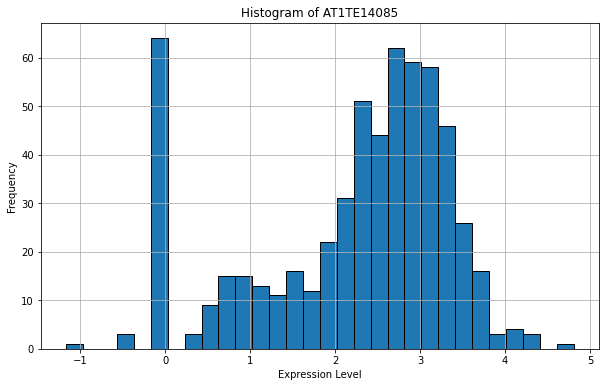

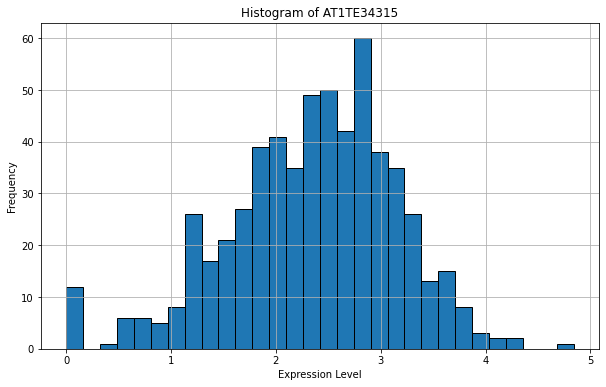

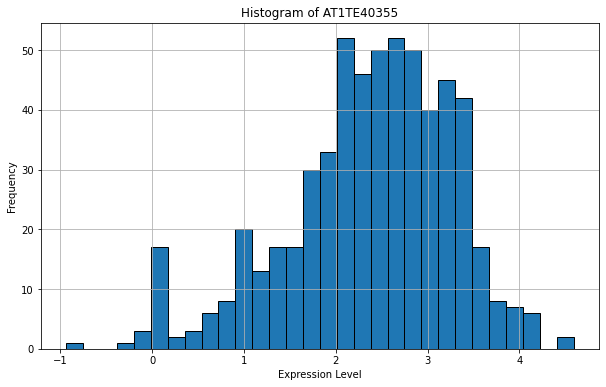

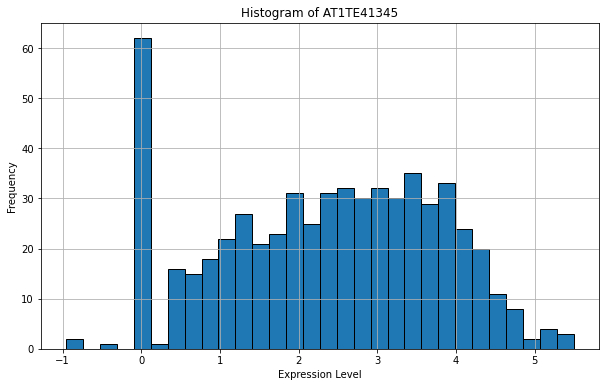

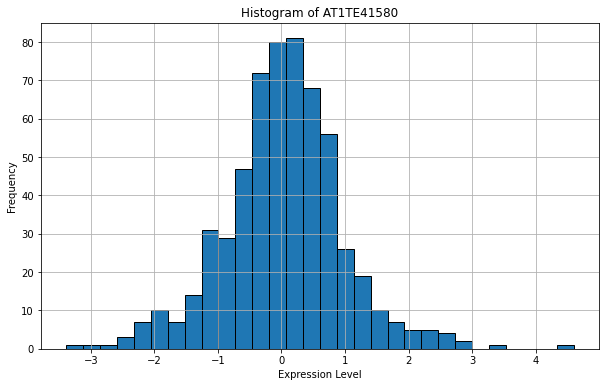

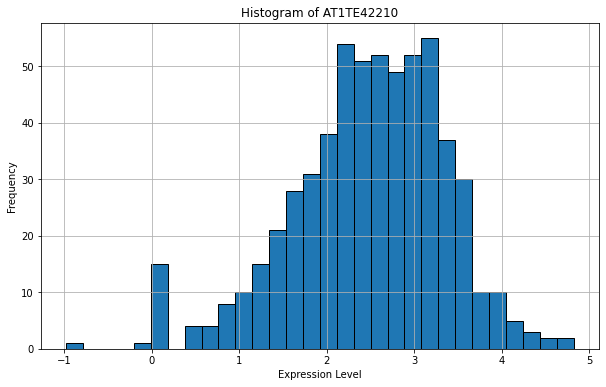

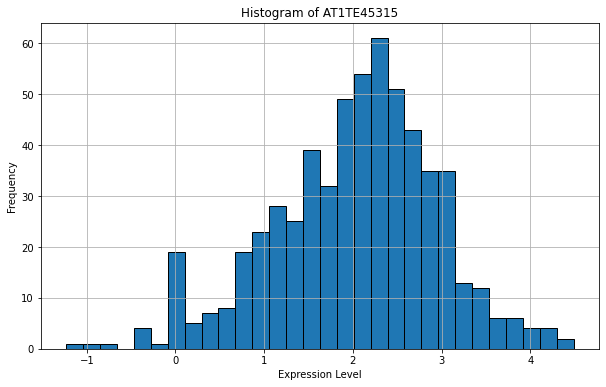

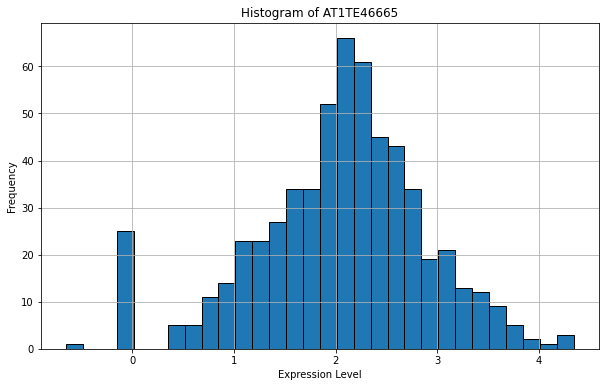

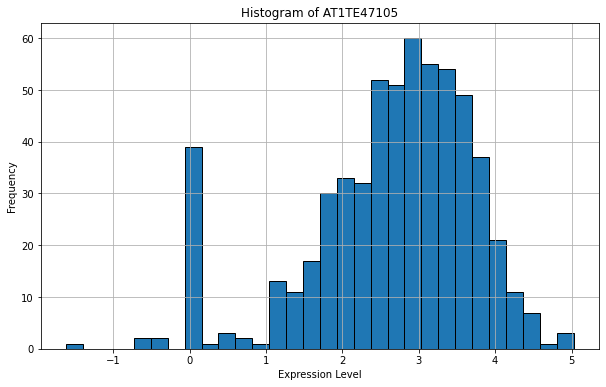

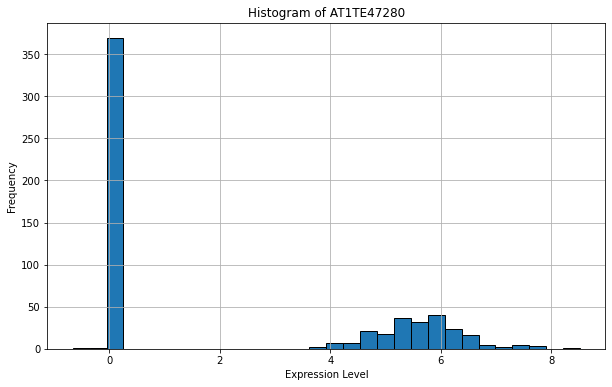

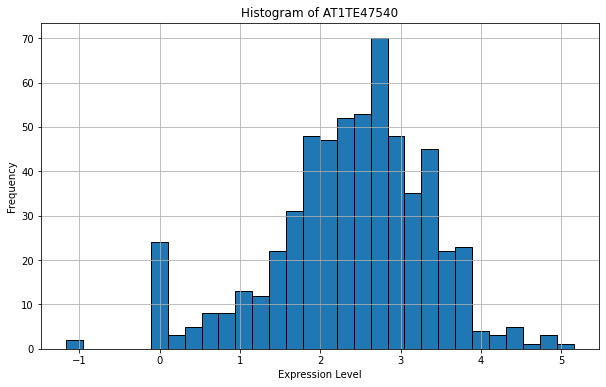

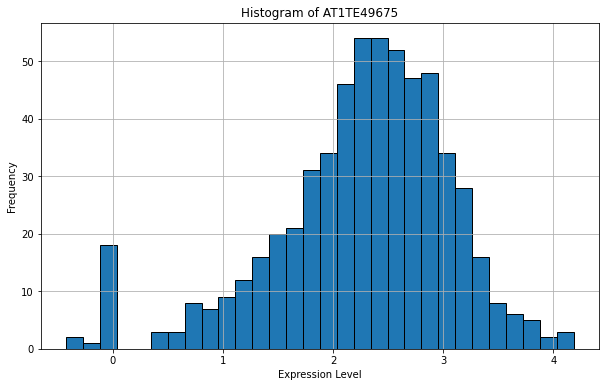

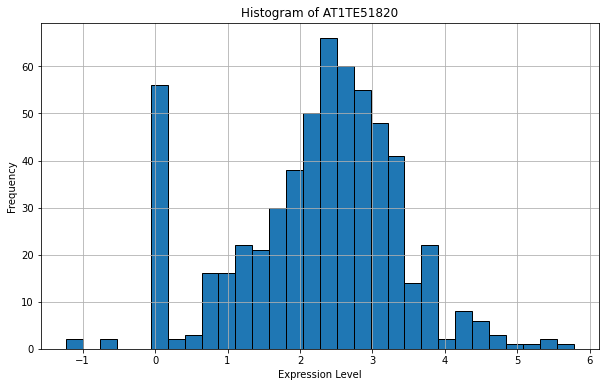

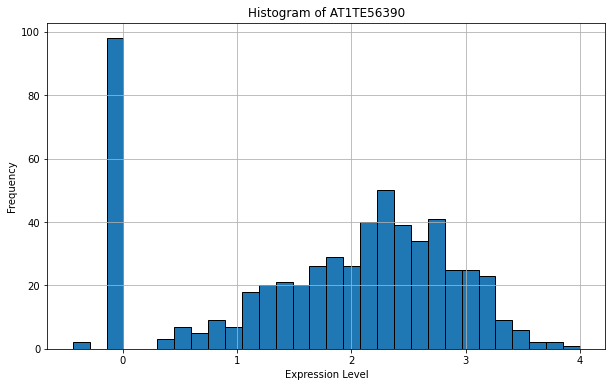

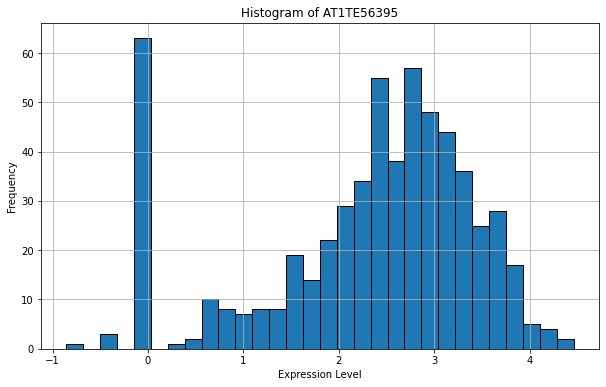

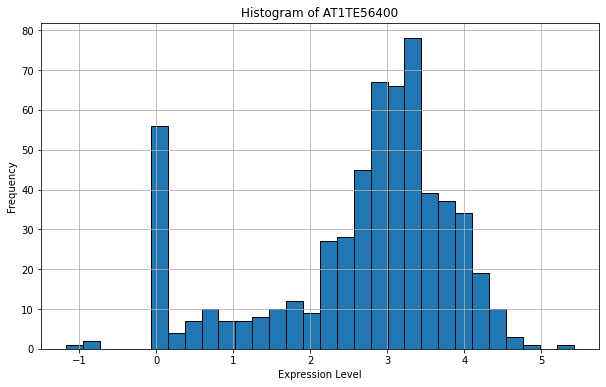

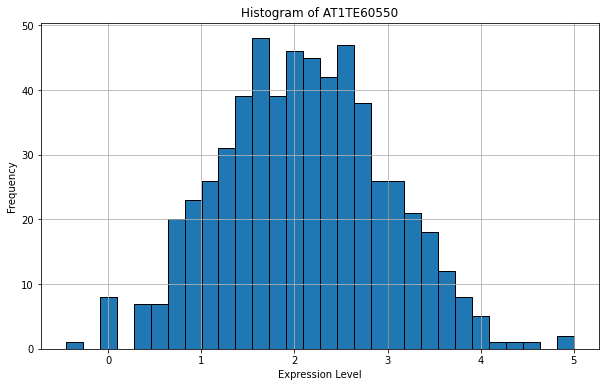

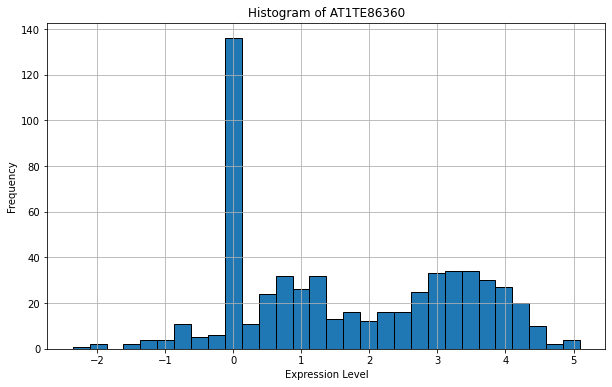

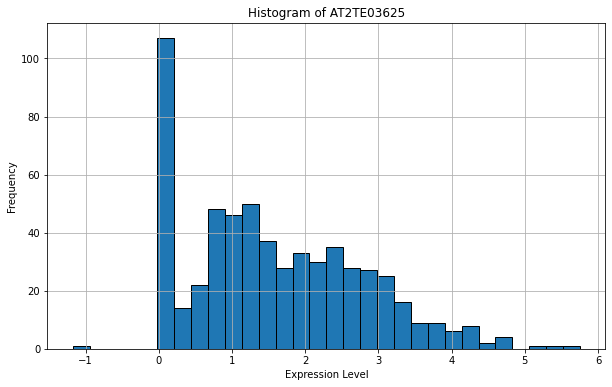

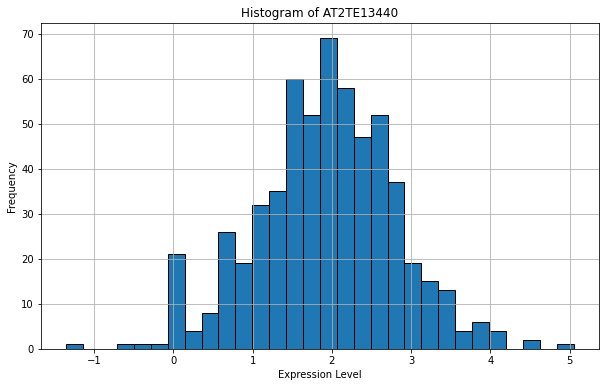

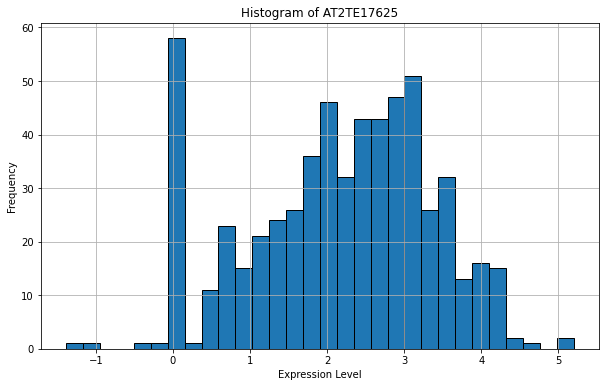

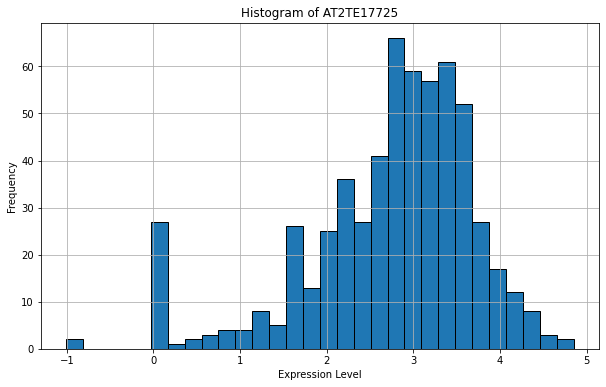

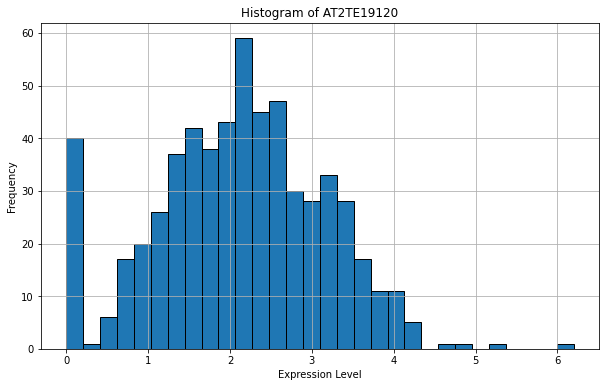

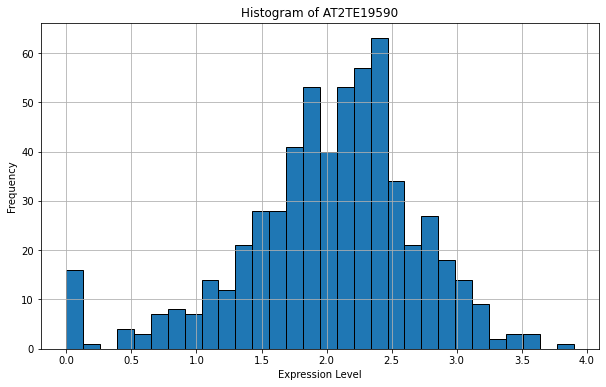

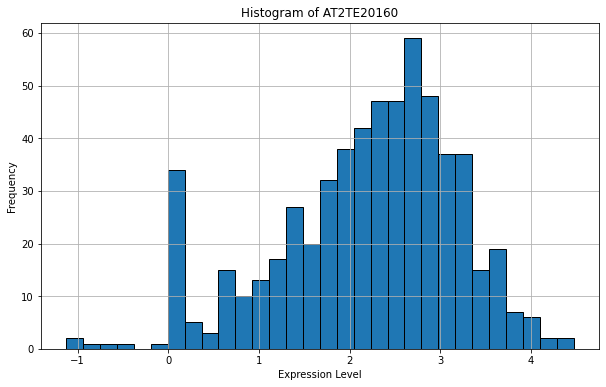

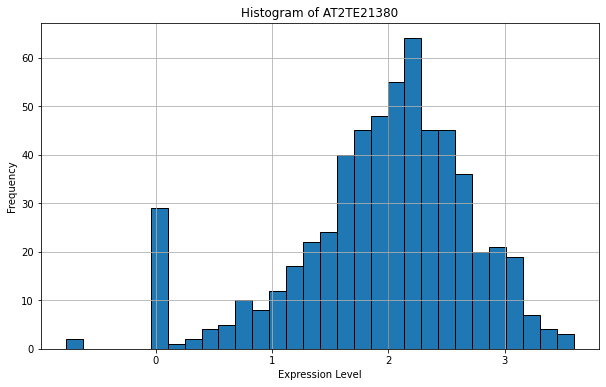

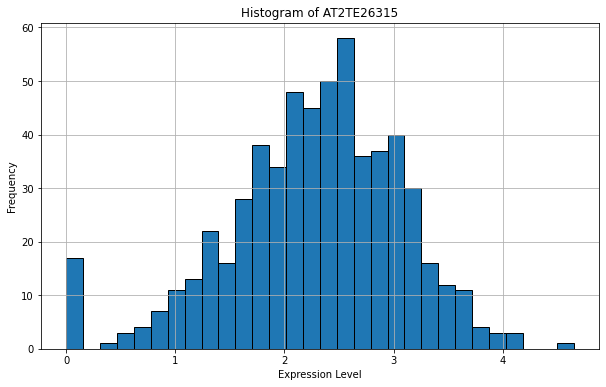

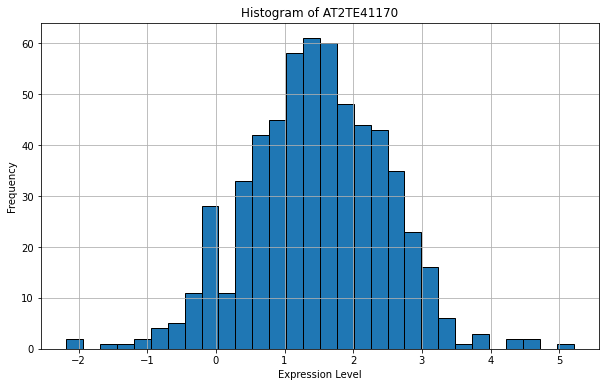

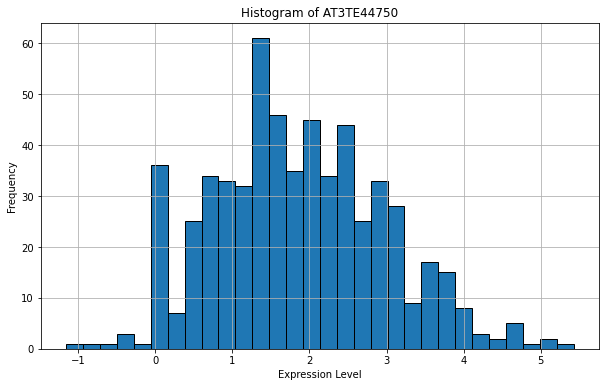

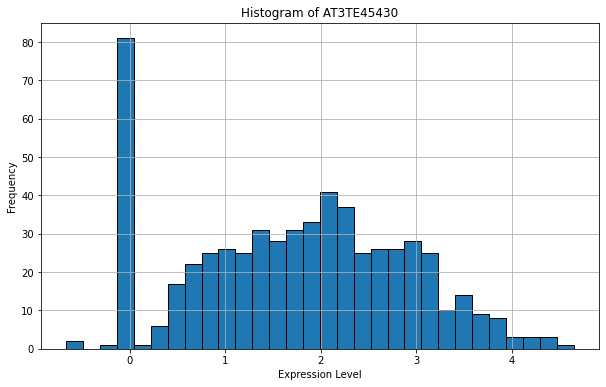

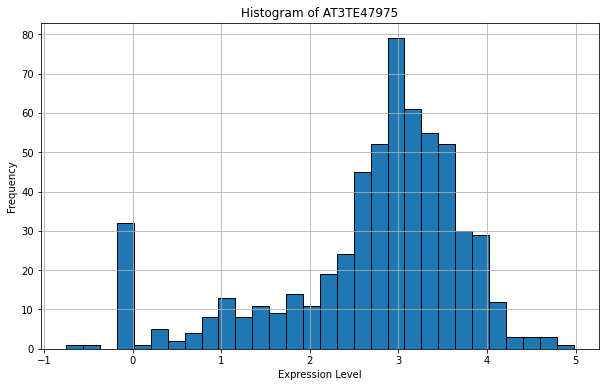

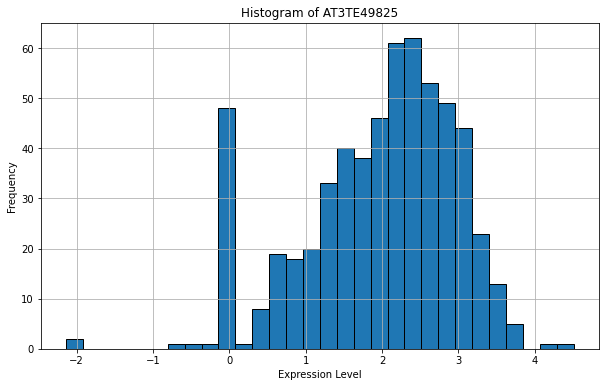

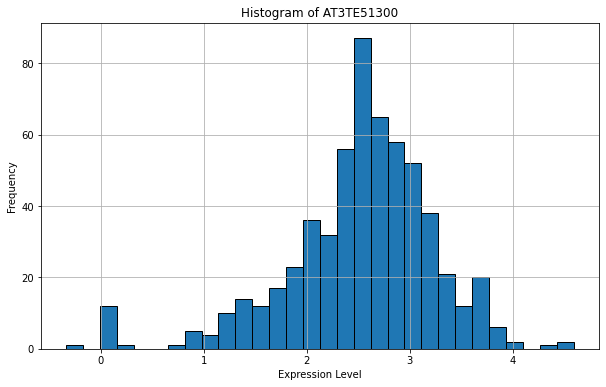

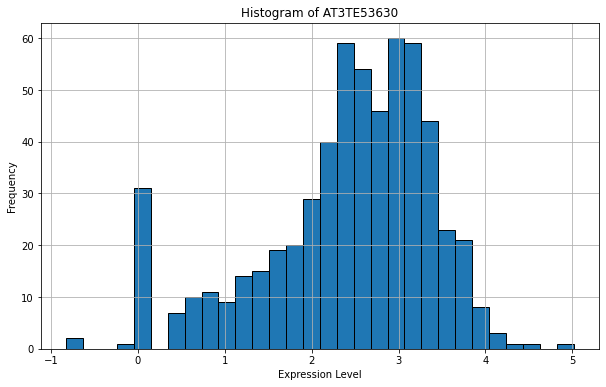

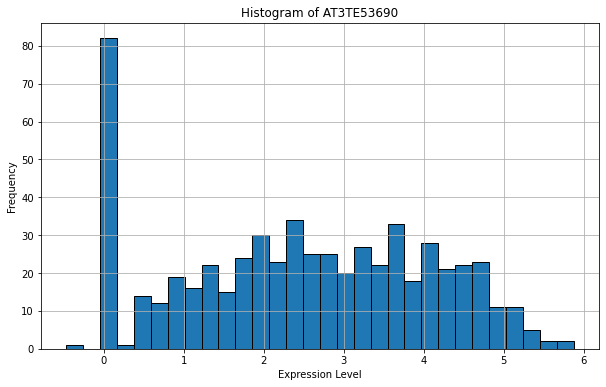

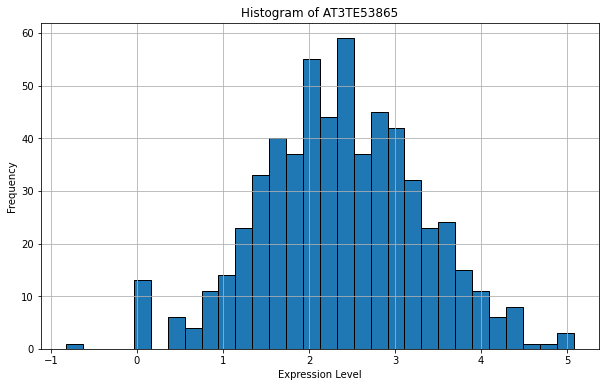

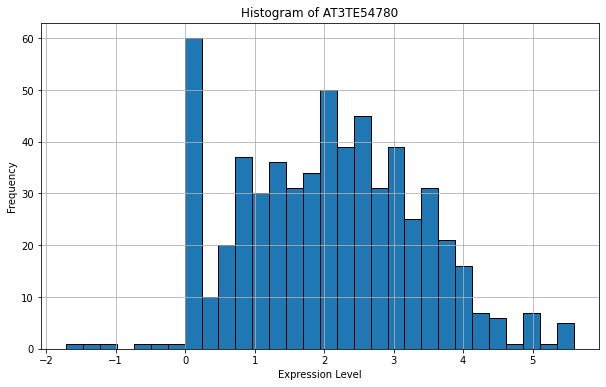

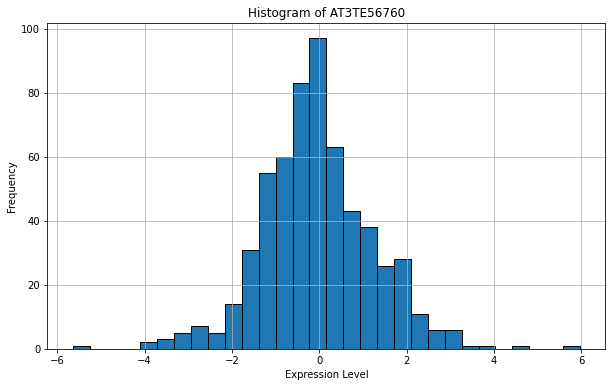

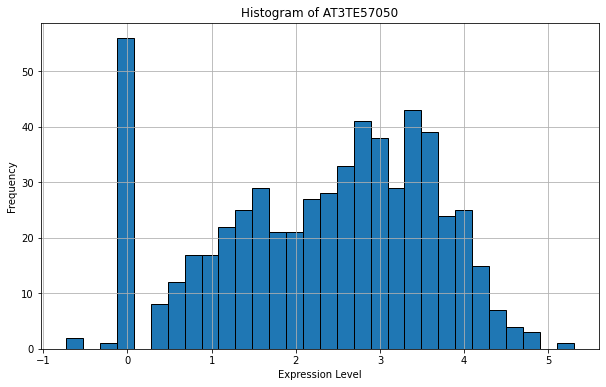

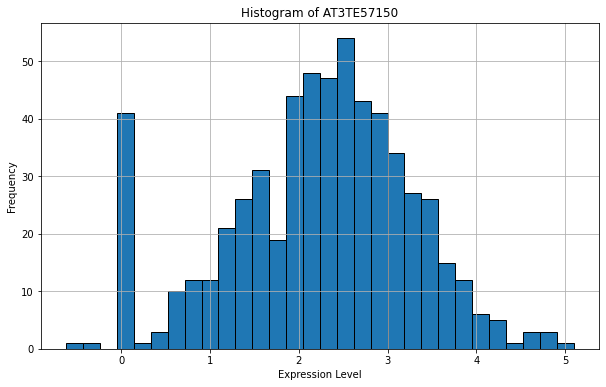

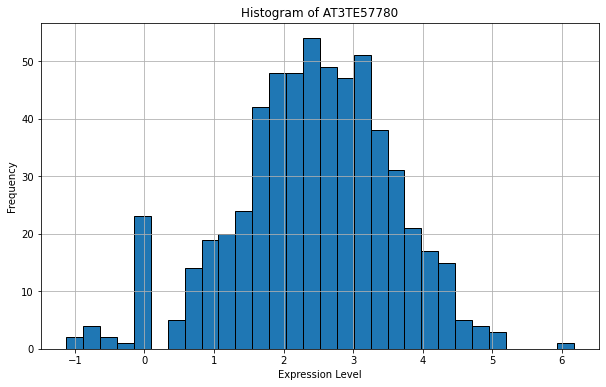

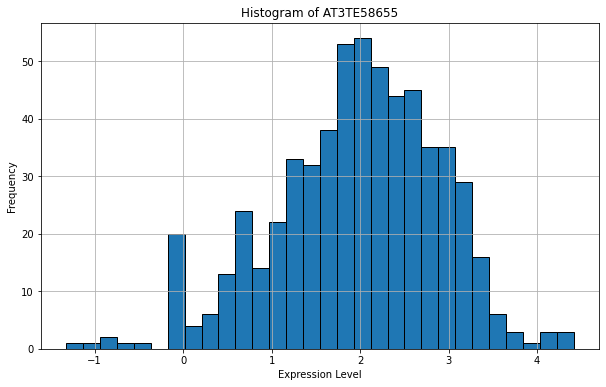

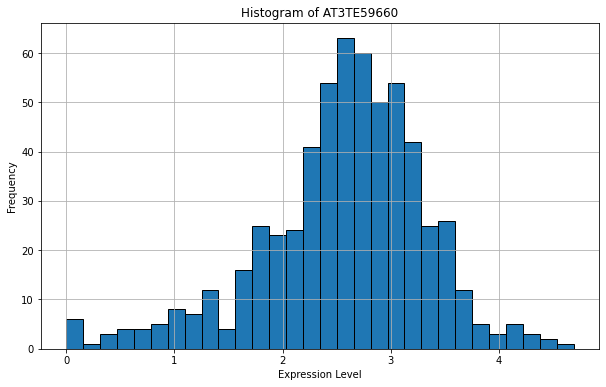

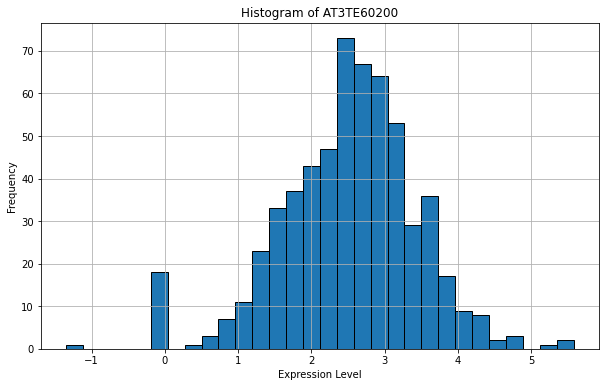

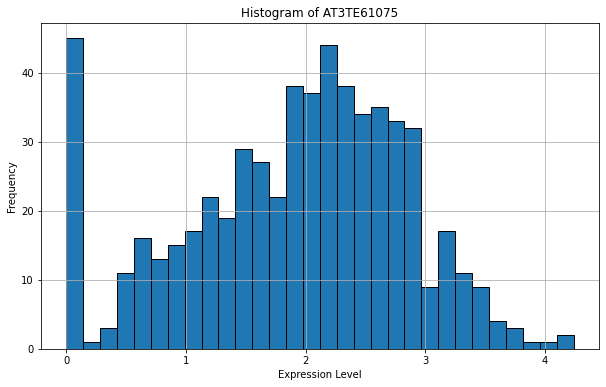

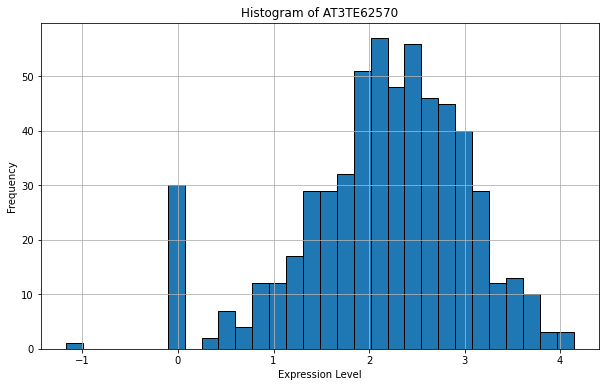

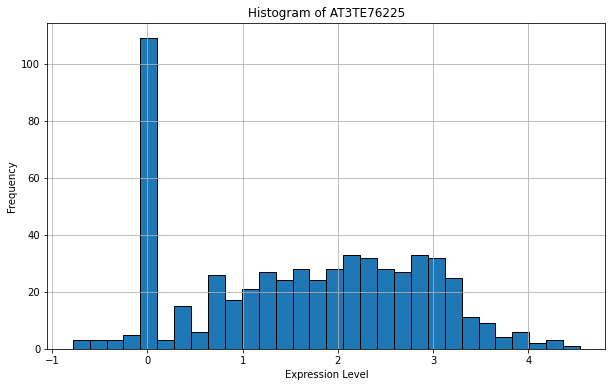

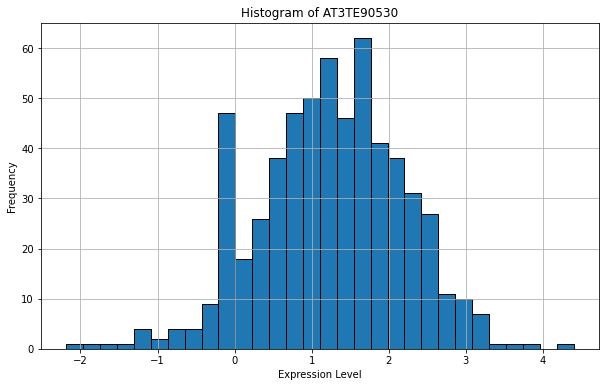

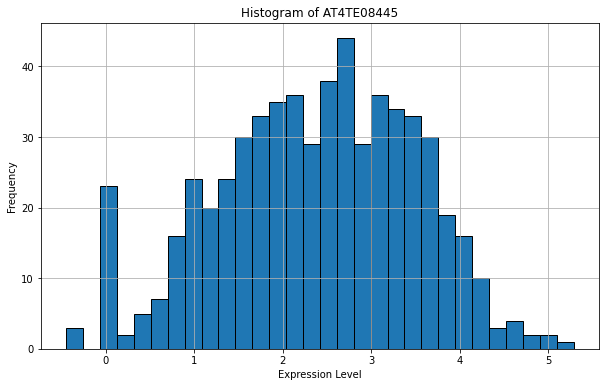

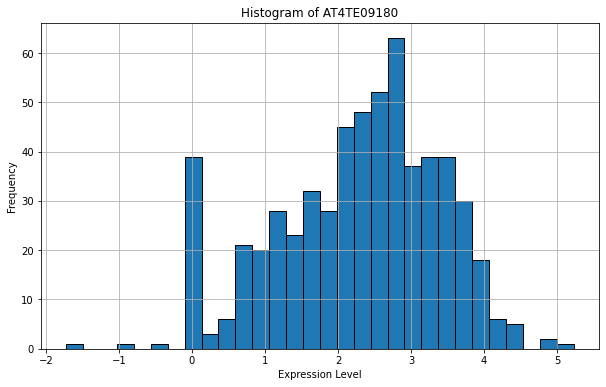

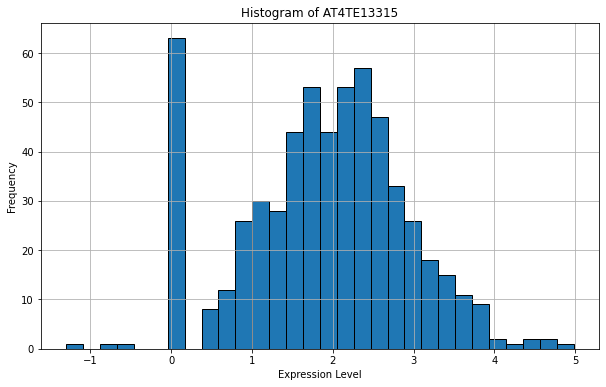

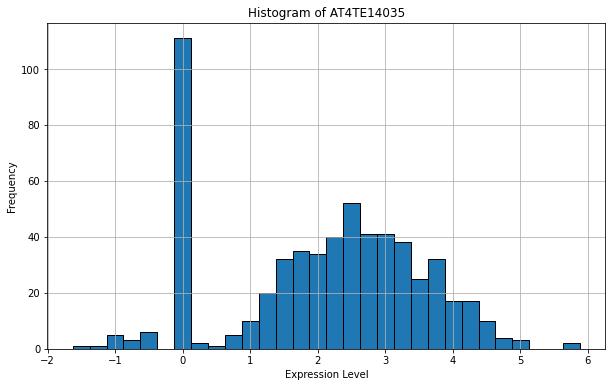

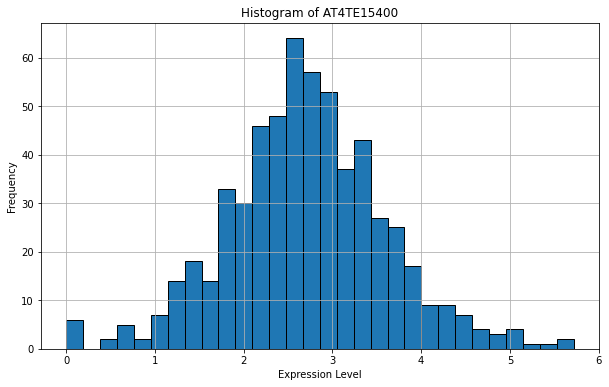

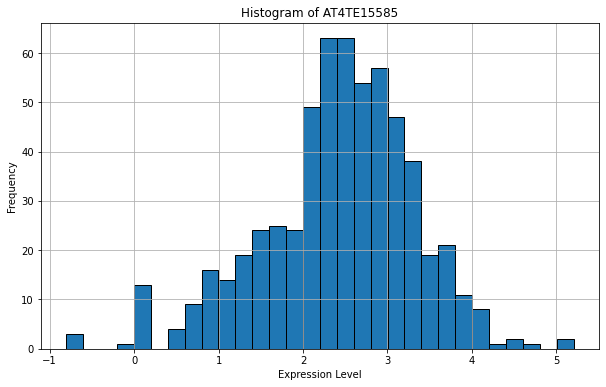

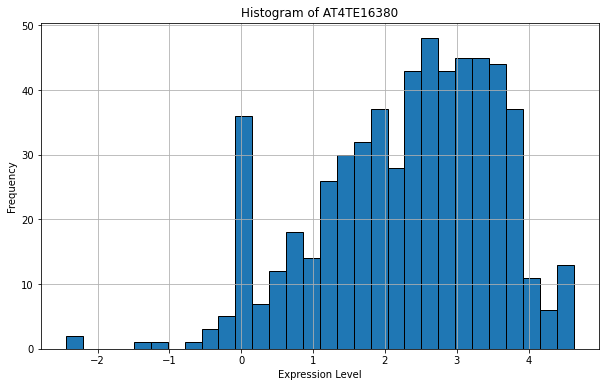

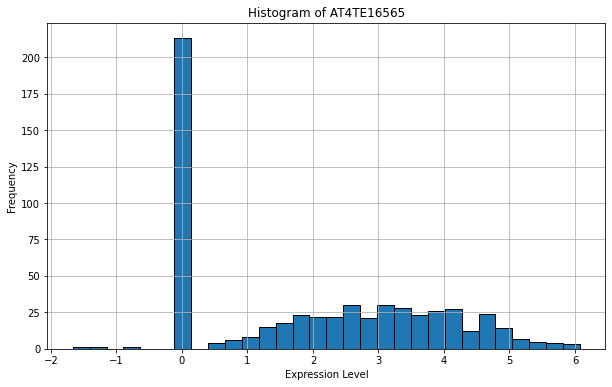

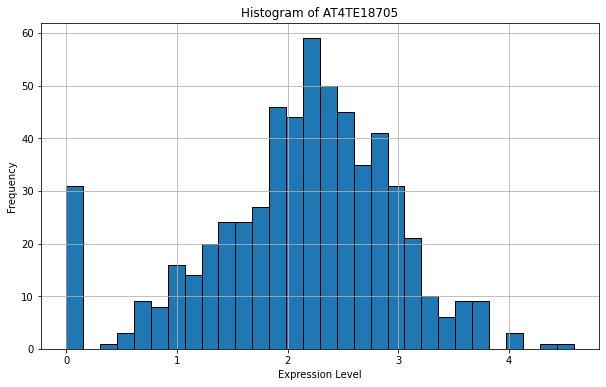

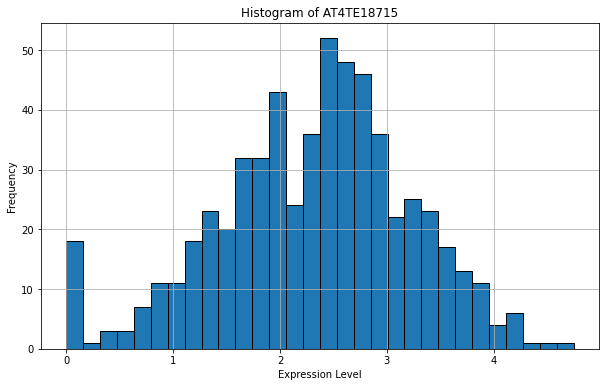

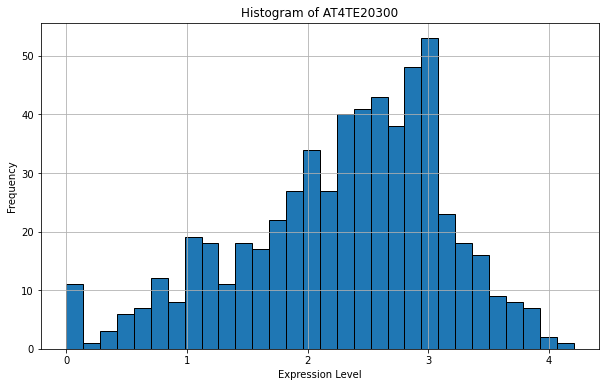

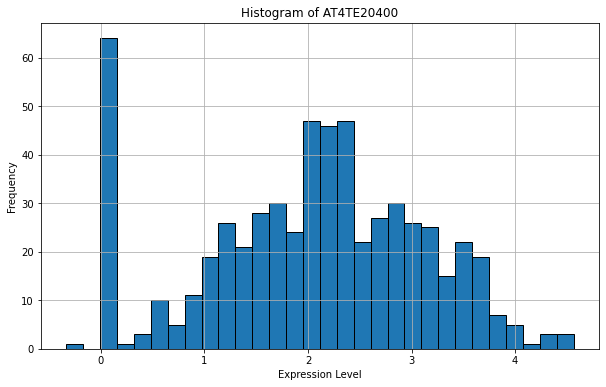

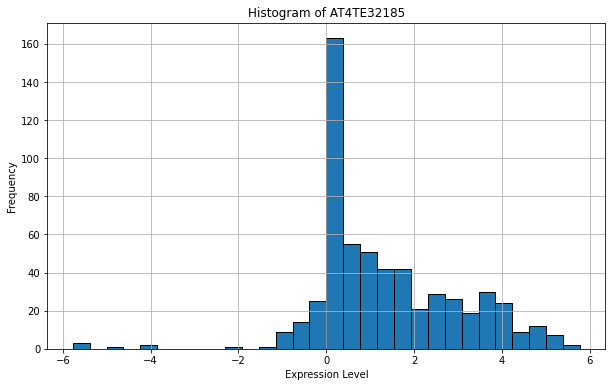

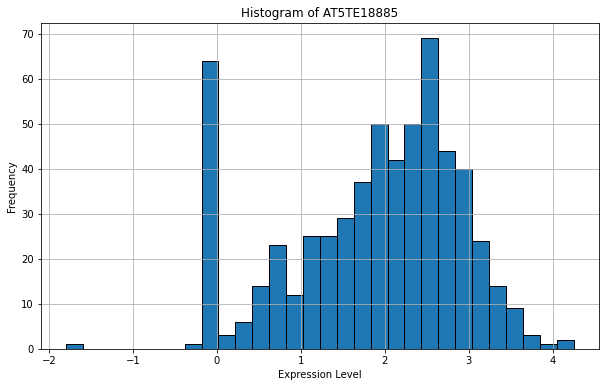

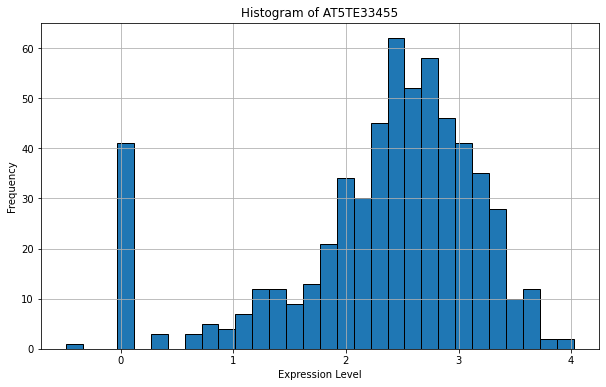

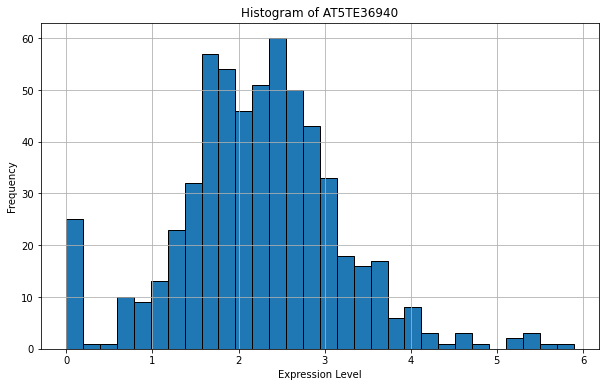

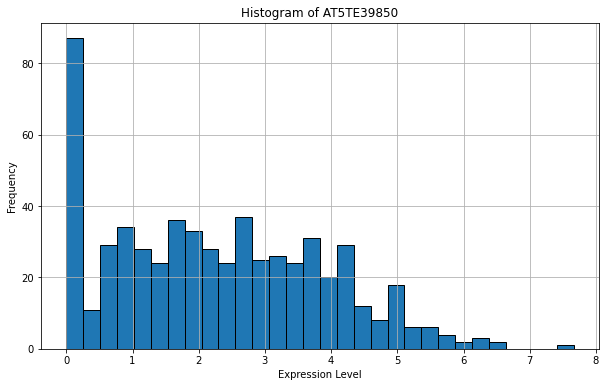

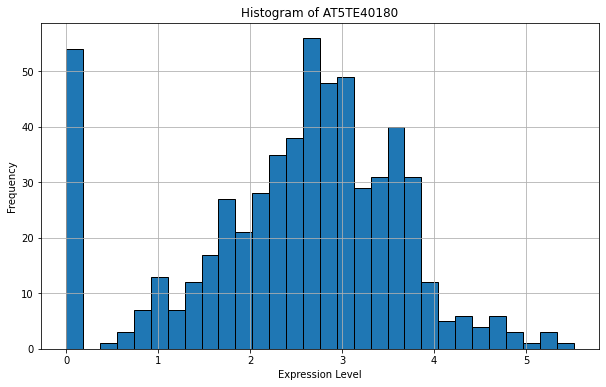

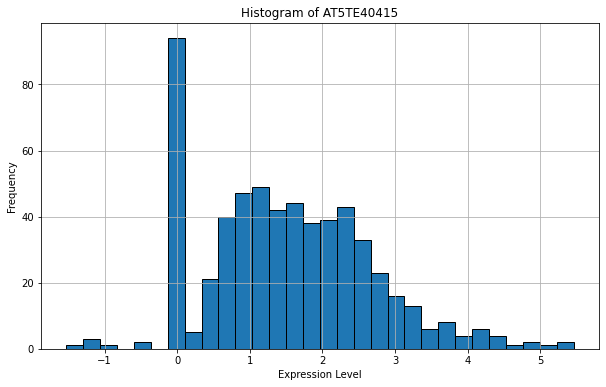

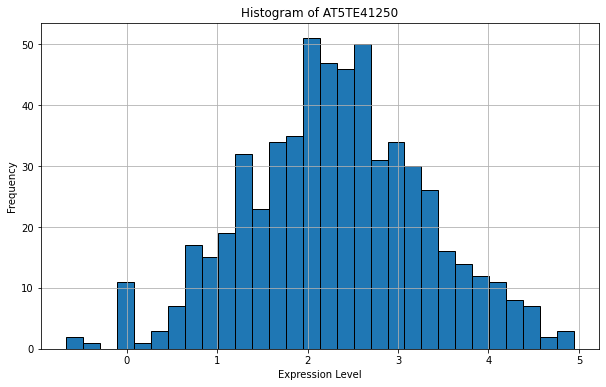

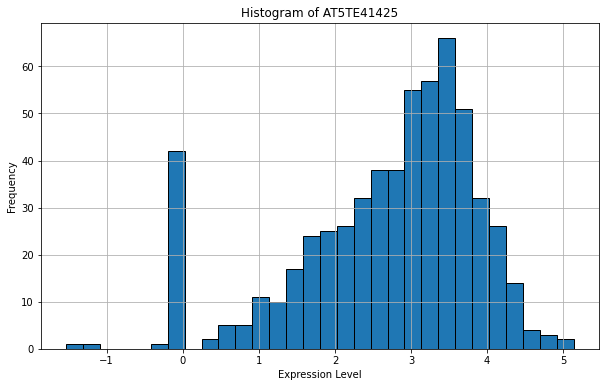

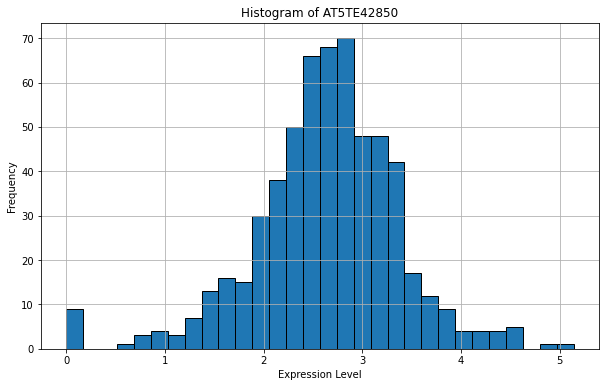

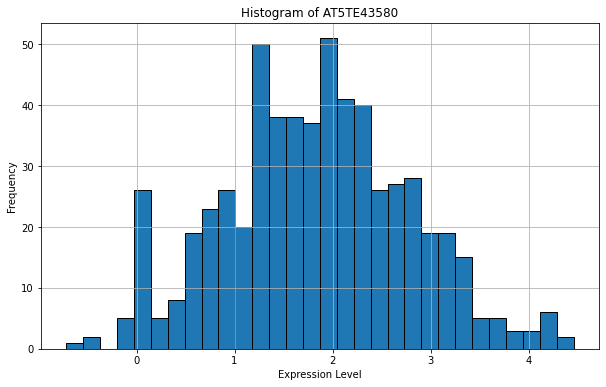

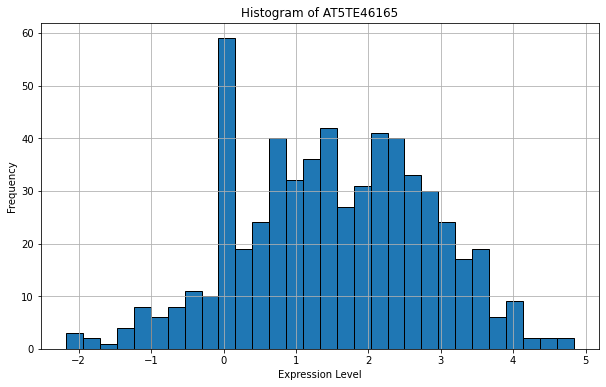

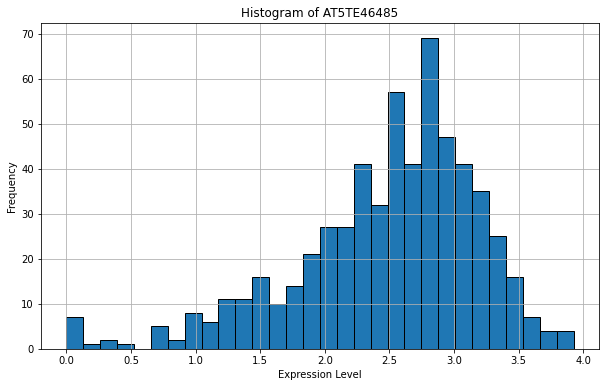

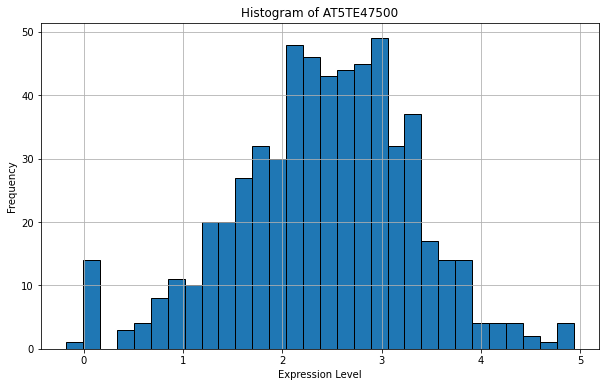

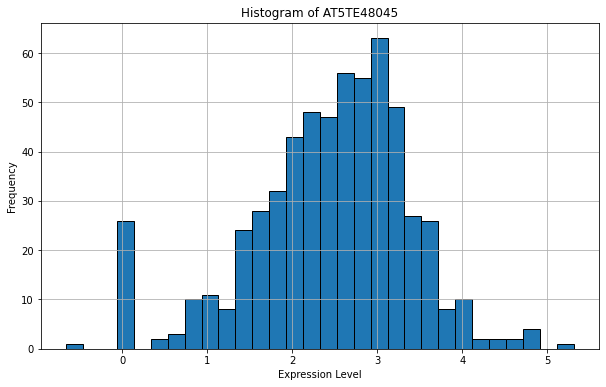

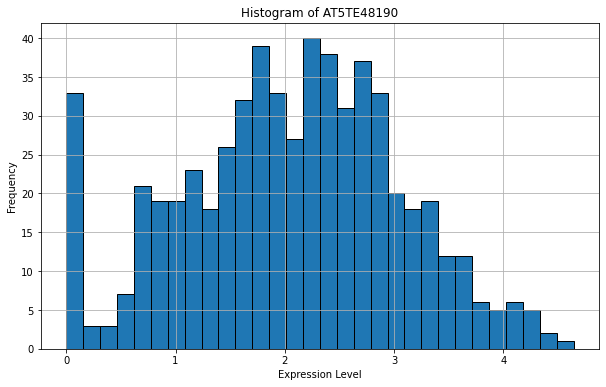

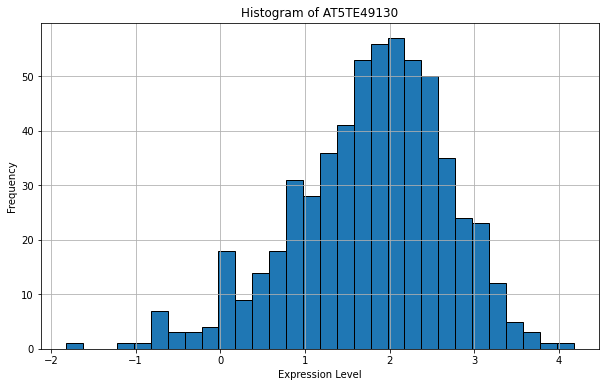

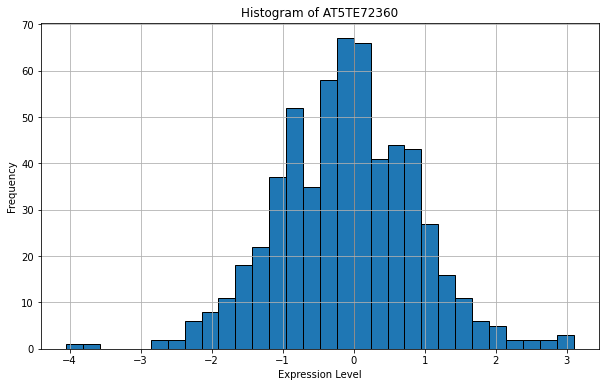

In [31]:
#Histogram of each TE 
te_columns = [col for col in diff_df.columns if col not in ['index', 'Replicate', 'accession']]

for te in te_columns:
    plt.figure(figsize=(10, 6))
    plt.hist(diff_df[te], bins=30, edgecolor='black')
    plt.title(f'Histogram of {te}')
    plt.xlabel('Expression Level')
    plt.ylabel('Frequency')
    plt.grid(True)
    plt.show()

In [ ]:
# Create a DataFrame from the rows list
    phenotype_data_final = pd.DataFrame(rows, columns=['Col1', 'Accession', 'Col2', 'Col3','Col4',f'{te}_Rep1', f'{te}_Rep2', f'{te}_Rep3'])

    # Save the final phenotype data for this TE into a .csv file (tab-separated)
    phenotype_data_final.to_csv(os.path.join(te_folder, f"{te}_phenotype_file.csv"), sep='\t', index=False, header=False)
